# Model 3 - Decision Tree (Member 3)

A Decision Tree asks a series of yes/no questions about the features. It is easy to explain and draw, but a deep tree overfits, so the depth is limited.

## 1. Load the final tables

The tables come from Section 11 of the main notebook (`ML_code.ipynb`): time-based split (train = 2008/09-2013/14, test = 2014/15-2015/16), engineered features, no leakage columns.

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
import pandas as pd, numpy as np, json, warnings
import matplotlib.pyplot as plt, seaborn as sns
from sklearn.model_selection import GridSearchCV, TimeSeriesSplit
from sklearn.metrics import (accuracy_score, f1_score, log_loss, classification_report,
                             confusion_matrix, ConfusionMatrixDisplay)
warnings.filterwarnings("ignore")

# Path to Google Drive directory where the models and tables are stored
data_path = "/content/drive/MyDrive/Y3S1/Assignment/Models/"

# Load the final tables using the absolute Google Drive path
train      = pd.read_csv(data_path + "train_final.csv", parse_dates=["date"]).sort_values(["date", "match_api_id"])
test       = pd.read_csv(data_path + "test_final.csv", parse_dates=["date"])
train_odds = pd.read_csv(data_path + "train_final_odds.csv", parse_dates=["date"]).sort_values(["date", "match_api_id"])
test_odds  = pd.read_csv(data_path + "test_final_odds.csv", parse_dates=["date"])
feats = json.load(open(data_path + "final_feature_sets.json"))

# Two experiments: our own features only, and our features + bookmaker odds
experiments = {
    "No odds":   (train,      test,      feats["features_no_odds"]),
    "With odds": (train_odds, test_odds, feats["features_with_odds"]),
}
class_names = ["Away win", "Draw", "Home win"]      # target: 0 = A, 1 = D, 2 = H
for name, (tr, te, cols) in experiments.items():
    print(f"{name:10s} train {tr.shape[0]:6d} | test {te.shape[0]:5d} | features {len(cols)}")

No odds    train  19328 | test  6651 | features 16
With odds  train  16783 | test  5809 | features 18


In [ ]:
import pandas as pd, numpy as np, json, warnings
import matplotlib.pyplot as plt, seaborn as sns
from sklearn.model_selection import GridSearchCV, TimeSeriesSplit
from sklearn.metrics import (accuracy_score, f1_score, log_loss, classification_report,
                             confusion_matrix, ConfusionMatrixDisplay)
warnings.filterwarnings("ignore")

# Path to Google Drive directory where the models and tables are stored
data_path = "/content/drive/MyDrive/Y3S1/Assignment/Models/"

# Load the final tables using the absolute Google Drive path
train      = pd.read_csv(data_path + "train_final.csv", parse_dates=["date"]).sort_values(["date", "match_api_id"])
test       = pd.read_csv(data_path + "test_final.csv", parse_dates=["date"])
train_odds = pd.read_csv(data_path + "train_final_odds.csv", parse_dates=["date"]).sort_values(["date", "match_api_id"])
test_odds  = pd.read_csv(data_path + "test_final_odds.csv", parse_dates=["date"])
feats = json.load(open(data_path + "final_feature_sets.json"))

# Two experiments: our own features only, and our features + bookmaker odds
experiments = {
    "No odds":   (train,      test,      feats["features_no_odds"]),
    "With odds": (train_odds, test_odds, feats["features_with_odds"]),
}
class_names = ["Away win", "Draw", "Home win"]      # target: 0 = A, 1 = D, 2 = H
for name, (tr, te, cols) in experiments.items():
    print(f"{name:10s} train {tr.shape[0]:6d} | test {te.shape[0]:5d} | features {len(cols)}")

No odds    train  19328 | test  6651 | features 16
With odds  train  16783 | test  5809 | features 18


## 2. Evaluation helper

The test set is used **only once**, after tuning. Metrics: accuracy, macro F1 (main metric), weighted F1, log loss and draw recall.

In [ ]:
def evaluate(model, X, y, label, exp):
    """Test-set metrics. Macro F1 is the main metric because draws are the hardest class."""
    pred = model.predict(X)
    proba = model.predict_proba(X) if hasattr(model, "predict_proba") else None
    report = classification_report(y, pred, output_dict=True, zero_division=0)
    return {"model": label, "features": exp,
            "accuracy": round(accuracy_score(y, pred), 4),
            "macro_F1": round(f1_score(y, pred, average="macro"), 4),
            "weighted_F1": round(f1_score(y, pred, average="weighted"), 4),
            "log_loss": round(log_loss(y, proba), 4) if proba is not None else np.nan,
            "draw_recall": round(report["1"]["recall"], 4)}

def show_confusion(model, X, y, title):
    ConfusionMatrixDisplay.from_predictions(y, model.predict(X), display_labels=class_names, cmap="Blues", colorbar=False)
    plt.title(title)
    plt.show()

## 3. Tune and train the Decision Tree

Shallow trees (`max_depth` 3-8) and a minimum leaf size keep the tree simple and reduce overfitting.

Hyper-parameters are tuned with `GridSearchCV` and `TimeSeriesSplit` **inside the training data only** (each fold validates on a later period than it trains on), scored by macro F1.

No odds | best parameters: {'max_depth': 3, 'min_samples_leaf': 20} | CV macro F1: 0.4266


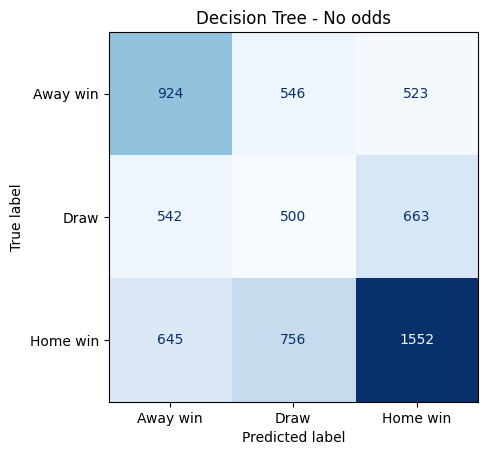

With odds | best parameters: {'max_depth': 3, 'min_samples_leaf': 20} | CV macro F1: 0.4638


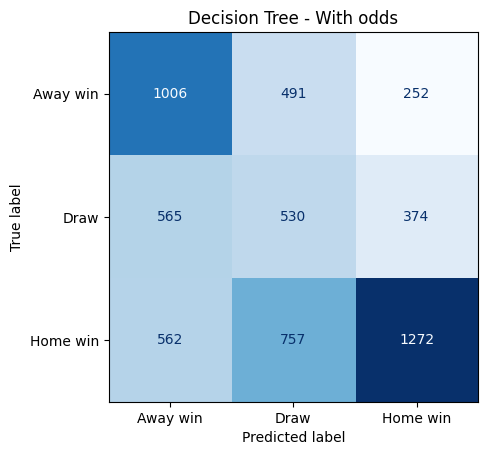

In [ ]:
from sklearn.tree import DecisionTreeClassifier, plot_tree

model = DecisionTreeClassifier(class_weight='balanced', random_state=42)
grid = {'max_depth': [3, 4, 5, 6, 8], 'min_samples_leaf': [20, 50, 100]}

results, best_models = [], {}
cv = TimeSeriesSplit(n_splits=3)

for exp, (tr, te, cols) in experiments.items():
    X_tr, y_tr, X_te, y_te = tr[cols], tr["target"], te[cols], te["target"]
    search = GridSearchCV(model, grid, cv=cv, scoring="f1_macro", n_jobs=-1)
    search.fit(X_tr, y_tr)
    best_models[exp] = search.best_estimator_
    print(exp, "| best parameters:", search.best_params_, "| CV macro F1:", round(search.best_score_, 4))
    results.append(evaluate(search.best_estimator_, X_te, y_te, "Decision Tree", exp))
    show_confusion(search.best_estimator_, X_te, y_te, f"Decision Tree - {exp}")

## 4. Results on the test seasons (2014/15 - 2015/16)

In [ ]:
results_table = pd.DataFrame(results)
results_table.to_csv("results_03_decision_tree.csv", index=False)
results_table

,model,features,accuracy,macro_F1,weighted_F1,log_loss,draw_recall
0,Decision Tree,No odds,0.4475,0.4270,0.4502,1.0535,0.2933
1,Decision Tree,With odds,0.4834,0.4705,0.4914,1.0036,0.3608


In [ ]:
from google.colab import files
files.download('results_03_decision_tree.csv')

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## 5. Interpretation of the model

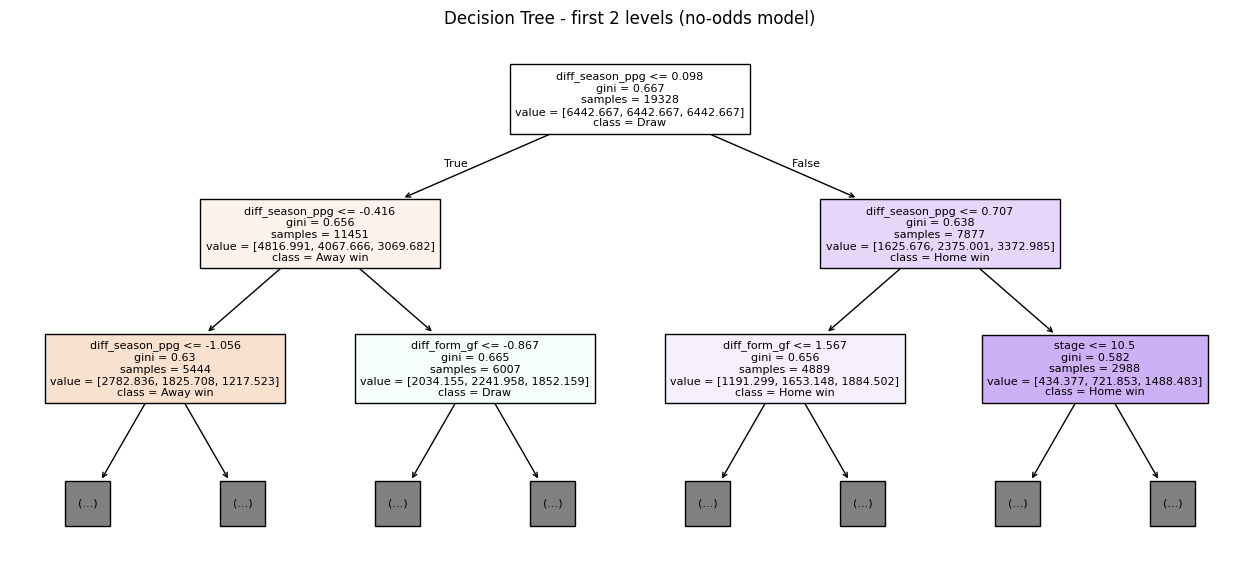


Top features - No odds
diff_season_ppg    0.931
stage              0.041
diff_form_gf       0.029
league_1           0.000
league_7809        0.000
league_10257       0.000
dtype: float64

Top features - With odds
prob_H         0.975
prob_D         0.025
league_1       0.000
stage          0.000
league_1729    0.000
league_4769    0.000
dtype: float64


In [ ]:
# Draw the top of the tree (no-odds model) and show feature importance
cols = experiments["No odds"][2]
plt.figure(figsize=(16, 7))
plot_tree(best_models["No odds"], feature_names=cols, class_names=class_names, max_depth=2, filled=True, fontsize=8)
plt.title("Decision Tree - first 2 levels (no-odds model)")
plt.show()

for exp, (tr, te, cols) in experiments.items():
    imp = pd.Series(best_models[exp].feature_importances_, index=cols).sort_values(ascending=False).head(6)
    print(f"\nTop features - {exp}")
    print(imp.round(3))

In [ ]:
from google.colab import files

files.download('results_03_decision_tree.csv')

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>